# Многоиндексная модель с латентными факторами: проверка на синтетических данных

Модель из раздела 3:
$$
Y_{it}=c_i+X_{it}^\top P^\top\ell_i+\gamma_i^\top f_t+\varepsilon_{it},\qquad i\le n,\ t\le T.
$$
Наклоны $b_i=P^\top\ell_i$ лежат в $m$-мерном подпространстве, а в ошибке есть $r$ латентных факторов $f_t$, которые могут быть связаны с признаками.

Что проверяем:
1. алгоритм сходится и восстанавливает наклоны, индексы и факторы;
2. без учёта факторов оценки смещены, а с учётом получаются почти такими же, как у «оракула», которому факторы известны;
3. как ошибка зависит от длины рядов $T$, в том числе при $T<d$;
4. что будет, если ошибиться с числом факторов $r$;
5. как влияет сила связи признаков с факторами.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})
COL = {'ols': '#8a8f98', 'lr': '#c8500a', 'ols_or': '#9b7fc4', 'lr_or': '#2a9d8f',
       'step0': '#e0a030', 'ours': '#1d5fbf'}

## 1. Данные

Генерируем данные так:
- индексы $\beta_1,\dots,\beta_m$ — плавные профили (синусы), ортонормированные;
- нагрузки на индексы $\ell_i\sim N\bigl((1.5,\ 0.5),\ 0.7^2I\bigr)$;
- факторы $f_t$ — процессы AR(1) с коэффициентом $\rho=0.6$ и единичной дисперсией;
- нагрузки на факторы $\gamma_i\sim N\bigl((1,\ 0),\ I\bigr)$;
- признаки $X_{it}=\Phi_if_t+v_{it}$, где элементы $\Phi_i$ распределены как $N(0,\mathrm{conf}^2)$, а $v_{it}\sim N(0,I_d)$. Параметр `conf` задаёт силу связи признаков с факторами, при `conf = 0` связи нет;
- $c_i\sim N(0,1)$, $\varepsilon_{it}\sim N(0,\sigma^2)$.

In [2]:
def make_data(n=100, T=200, d=20, m=2, r=2, conf=0.5, sigma=1.0, rho=0.6, seed=0):
    rng = np.random.default_rng(seed)
    j = np.arange(1, d + 1)
    P = np.vstack([np.sin(np.pi * k * j / (d + 1)) for k in range(1, m + 1)])
    P /= np.linalg.norm(P, axis=1, keepdims=True)                  # строки ортонормированы
    L = rng.normal(size=(n, m)) * 0.7 + np.r_[1.5, 0.5, 0.0, 0.0][:m]
    B = L @ P                                                      # матрица наклонов n x d, ранг m
    F = np.zeros((T, r)); f = np.zeros(r)                          # факторы: AR(1)
    e = rng.normal(size=(T + 50, r))
    for t in range(T + 50):
        f = rho * f + np.sqrt(1 - rho ** 2) * e[t]
        if t >= 50:
            F[t - 50] = f
    G = rng.normal(size=(n, r)) + np.eye(1, r)[0]                  # нагрузки на факторы
    Phi = conf * rng.normal(size=(n, d, r))                        # связь признаков с факторами
    X = np.einsum('idk,tk->itd', Phi, F) + rng.normal(size=(n, T, d))
    c = rng.normal(size=n)
    Y = c[:, None] + np.einsum('itd,id->it', X, B) + G @ F.T + sigma * rng.normal(size=(n, T))
    return dict(Y=Y, X=X, P=P, L=L, B=B, F=F, G=G, c=c)

## 2. Алгоритм

Функции повторяют шаги раздела 3:

| функция | что делает | в тексте |
|---|---|---|
| `basis` | ортонормированный базис $\bar H$ пространства $\mathrm{span}(\mathbf 1_T,F)$ | исключение факторов проекцией |
| `proj_stats` | проецированные сводные статистики $Z_i^F,\ \widehat G_i^F$ | там же |
| `ols_slopes` | $\hat b_i=(\widehat G_i^F)^{-1}Z_i^F$ | лемма |
| `lowrank_slopes` | чередование $\ell_i\leftrightarrow B$, затем главные оси | шаг по наклонам |
| `factor_step` | первые $r$ главных компонент матрицы остатков | оценка факторов при известных наклонах |
| `init_factors` | главные компоненты всей панели (ряды $Y$ и все ряды $X$) | начальное приближение |
| `fit` | весь алгоритм | алгоритм |

In [3]:
def basis(F, T):
    # ортонормированный базис span(1, F), матрица T x (r+1)
    H = np.ones((T, 1)) if F is None or F.shape[1] == 0 else np.column_stack([np.ones(T), F])
    return np.linalg.qr(H)[0]


def proj_stats(X, Y, Hb):
    # Z_i = X_i^T M Y_i,  G_i = X_i^T M X_i,  где M = I - Hb Hb^T
    MX = X - np.einsum('tk,ikd->itd', Hb, np.einsum('tk,itd->ikd', Hb, X))
    return np.einsum('itd,ite->ide', MX, MX), np.einsum('itd,it->id', MX, Y)


def ols_slopes(G, Z):
    return np.linalg.solve(G, Z[..., None])[..., 0]


def principal_axes(Bmat, m):
    # первые m главных осей облака наклонов (PCA без центрирования)
    return np.linalg.svd(Bmat, full_matrices=False)[2][:m]


def lowrank_slopes(G, Z, P0, iters=5, lam=0.0, tol=1e-10):
    # минимизация sum_i (b_i^T G_i b_i - 2 b_i^T Z_i) при b_i = B^T l_i
    n, d = Z.shape; m = P0.shape[0]
    Bm, prev = P0.copy(), np.inf
    for _ in range(iters):
        BG = np.einsum('ka,iab->ikb', Bm, G)
        Lm = np.linalg.solve(np.einsum('ikb,lb->ikl', BG, Bm),
                             np.einsum('ka,ia->ik', Bm, Z)[..., None])[..., 0]       # шаг по l_i
        A = np.einsum('ik,il,iab->kalb', Lm, Lm, G).reshape(m * d, m * d)          # sum l l^T (x) G
        rhs = np.einsum('ik,ia->ka', Lm, Z).reshape(m * d)                         # sum l (x) Z
        Bm = np.linalg.solve(A + lam * np.eye(m * d), rhs + lam * P0.reshape(-1)).reshape(m, d)
        Bmat = Lm @ Bm
        obj = np.einsum('ia,iab,ib->', Bmat, G, Bmat) - 2 * np.sum(Bmat * Z)
        if prev - obj < tol * (abs(obj) + 1):
            break
        prev = obj
    P = principal_axes(Bmat, m)                                    # переход к главным осям
    return P, Bmat @ P.T, Bmat


def factor_step(Y, X, Bmat, r):
    # факторы = первые r главных компонент центрированной матрицы остатков n x T
    W = Y - np.einsum('itd,id->it', X, Bmat)
    W = W - W.mean(axis=1, keepdims=True)
    _, s, Vt = np.linalg.svd(W, full_matrices=False)
    return np.sqrt(Y.shape[1]) * Vt[:r].T, s


def ssr(Y, X, Bmat, Hb):
    # S = sum_i ||M (Y_i - X_i b_i)||^2  (c_i и gamma_i уже исключены)
    W = Y - np.einsum('itd,id->it', X, Bmat)
    return np.sum(W ** 2) - np.sum((W @ Hb) ** 2)


def init_factors(Y, X, r):
    # начальные факторы: главные компоненты всех рядов панели, каждый ряд центрирован и нормирован
    n, T, d = X.shape
    S = np.vstack([Y, X.transpose(0, 2, 1).reshape(n * d, T)])
    S = S - S.mean(axis=1, keepdims=True)
    S = S / (S.std(axis=1, keepdims=True) + 1e-12)
    return np.sqrt(T) * np.linalg.svd(S, full_matrices=False)[2][:r].T


def fit(Y, X, m, r, max_iter=500, tol=1e-9, inner=5, lam=0.0, F0=None):
    n, T, d = X.shape
    F = init_factors(Y, X, r) if F0 is None else F0
    if T > d + r + 1:                                              # старт: МНК при факторах F^(0)
        P = principal_axes(ols_slopes(*proj_stats(X, Y, basis(F, T))), m)
    else:                                                          # мало наблюдений: случайный старт
        P = np.linalg.qr(np.random.default_rng(0).normal(size=(d, m)))[0].T
    hist = []
    for it in range(max_iter):
        Hb = basis(F, T)
        G, Z = proj_stats(X, Y, Hb)                                # 2.1
        P, Lm, Bmat = lowrank_slopes(G, Z, P, iters=inner, lam=lam)  # 2.2
        hist.append(ssr(Y, X, Bmat, Hb))                           # 2.3
        if it > 0 and hist[-2] - hist[-1] < tol * hist[-1]:
            break
        F, _ = factor_step(Y, X, Bmat, r)                          # 2.4
    W = Y - np.einsum('itd,id->it', X, Bmat)                       # 3.1: c_i и gamma_i
    coef = np.linalg.lstsq(np.column_stack([np.ones(T), F]), W.T, rcond=None)[0].T
    return dict(P=P, L=Lm, B=Bmat, F=F, c=coef[:, 0], G=coef[:, 1:], hist=np.array(hist))


def fit_resid(Y, X, m, r, max_iter=1000, tol=1e-9, inner=5):
    # для сравнения: чередование по остаткам. При фиксированных (F, gamma) вычитаем факторную часть
    # и оцениваем наклоны; gamma при этом не пересчитываются вместе с наклонами
    n, T, d = X.shape
    F = init_factors(Y, X, r); H1 = basis(None, T)
    W = Y - Y.mean(1, keepdims=True); Gm = W @ F / T
    P, hist = None, []
    for it in range(max_iter):
        G, Z = proj_stats(X, Y - Gm @ F.T, H1)
        if P is None:
            P = principal_axes(ols_slopes(G, Z), m)
        P, Lm, Bmat = lowrank_slopes(G, Z, P, iters=inner)
        Wr = Y - np.einsum('itd,id->it', X, Bmat); Wr = Wr - Wr.mean(1, keepdims=True)
        F = np.sqrt(T) * np.linalg.svd(Wr, full_matrices=False)[2][:r].T
        Gm = Wr @ F / T
        hist.append(np.sum((Wr - Gm @ F.T) ** 2))
        if it > 0 and hist[-2] - hist[-1] < tol * hist[-1]:
            break
    return dict(P=P, B=Bmat, F=F, hist=np.array(hist))

Метрики:
- **ошибка наклонов** $\|\widehat{\mathcal B}-\mathcal B\|_F/\|\mathcal B\|_F$;
- **угол индексов**: синус наибольшего главного угла между найденным и истинным подпространством индексов. Ноль значит, что подпространства совпадают, единица — что они перпендикулярны. Сравниваем подпространства, а не сами векторы, потому что индексы определены только с точностью до поворота;
- **угол факторов**: то же для $\mathrm{span}(F)\subset\mathbb R^T$.

Сравниваем шесть способов оценки:

| способ | факторы | наклоны |
|---|---|---|
| МНК | не учитываются | отдельно по каждому индивиду |
| многоиндексный | не учитываются | низкий ранг, раздел 2 |
| МНК-оракул | истинные $F$ | отдельно по каждому индивиду |
| многоиндексный оракул | истинные $F$ | низкий ранг |
| шаг 0 | $F^{(0)}$ из начального приближения | отдельно по каждому индивиду |
| **наш метод** | оцениваются | низкий ранг, чередование |

«Оракулы» на практике недоступны, они показывают, какая точность вообще возможна.

In [4]:
def rel_err(Bh, B):
    return np.linalg.norm(Bh - B) / np.linalg.norm(B)


def sin_angle(A, B):
    # синус наибольшего главного угла между пространствами строк A и B
    Qa, Qb = np.linalg.qr(A.T)[0], np.linalg.qr(B.T)[0]
    return float(np.sqrt(max(0.0, 1 - np.linalg.svd(Qa.T @ Qb, compute_uv=False).min() ** 2)))


def all_methods(D, m=2, r=2):
    Y, X = D['Y'], D['X']; T = Y.shape[1]
    res = {}
    G, Z = proj_stats(X, Y, basis(None, T)); Bo = ols_slopes(G, Z)
    res['МНК'] = (Bo, principal_axes(Bo, m), None)
    P, _, Bl = lowrank_slopes(G, Z, principal_axes(Bo, m), iters=50)
    res['многоиндексный'] = (Bl, P, None)
    G, Z = proj_stats(X, Y, basis(D['F'], T)); Bo2 = ols_slopes(G, Z)
    res['МНК-оракул'] = (Bo2, principal_axes(Bo2, m), D['F'])
    P, _, Bl2 = lowrank_slopes(G, Z, principal_axes(Bo2, m), iters=50)
    res['многоиндексный оракул'] = (Bl2, P, D['F'])
    F0 = init_factors(Y, X, r); Bs0 = ols_slopes(*proj_stats(X, Y, basis(F0, T)))
    res['шаг 0'] = (Bs0, principal_axes(Bs0, m), F0)
    R = fit(Y, X, m, r)
    res['наш метод'] = (R['B'], R['P'], R['F'])
    return res, R


def table(res, D):
    rows = []
    for k, (Bh, Ph, Fh) in res.items():
        rows.append([k, rel_err(Bh, D['B']), sin_angle(Ph, D['P']),
                     np.nan if Fh is None else sin_angle(Fh.T, D['F'].T)])
    return pd.DataFrame(rows, columns=['способ', 'ошибка наклонов', 'угол индексов', 'угол факторов']).set_index('способ')

## 3. Один набор данных

Параметры: $n=100$ индивидов, $T=200$ моментов времени, $d=20$ признаков, $m=2$ индекса, $r=2$ фактора, `conf = 0.5`.

In [5]:
D = make_data(n=100, T=200, d=20, m=2, r=2, conf=0.5, seed=0)
t0 = time.time()
res, R = all_methods(D)
print(f'время: {time.time() - t0:.2f} с, итераций нашего метода: {len(R["hist"])}')
table(res, D).round(3)

время: 0.16 с, итераций нашего метода: 5


,ошибка наклонов,угол индексов,угол факторов
способ,,,
МНК,0.384,0.131,NaN
многоиндексный,0.363,0.287,NaN
МНК-оракул,0.186,0.049,0.000
многоиндексный оракул,0.057,0.044,0.000
шаг 0,0.186,0.049,0.057
наш метод,0.058,0.045,0.133


### Сходимость

Значение целевой функции $S$ на каждой итерации. Ни один шаг не должен его увеличивать.

S не возрастает: True


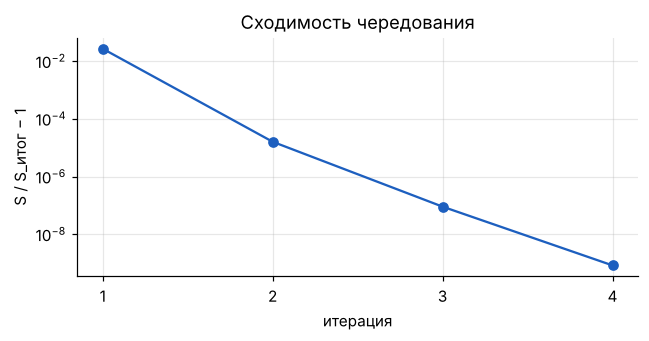

In [6]:
h = R['hist']
print('S не возрастает:', bool(np.all(np.diff(h) <= 1e-9 * h[0])))
fig, ax = plt.subplots(figsize=(6, 3.2))
it = np.arange(1, len(h))
ax.plot(it, h[:-1] / h[-1] - 1, 'o-', color=COL['ours'])
ax.set_yscale('log'); ax.set_xticks(it); ax.set_xlabel('итерация'); ax.set_ylabel('S / S_итог − 1')
ax.set_title('Сходимость чередования')
plt.tight_layout(); plt.show()

### Что нашёл алгоритм

Индексы и факторы определены с точностью до поворота, поэтому перед сравнением поворачиваем оценки к истине: для индексов — ортогональной матрицей (задача Прокруста), для факторов — линейной регрессией истинных факторов на найденные.

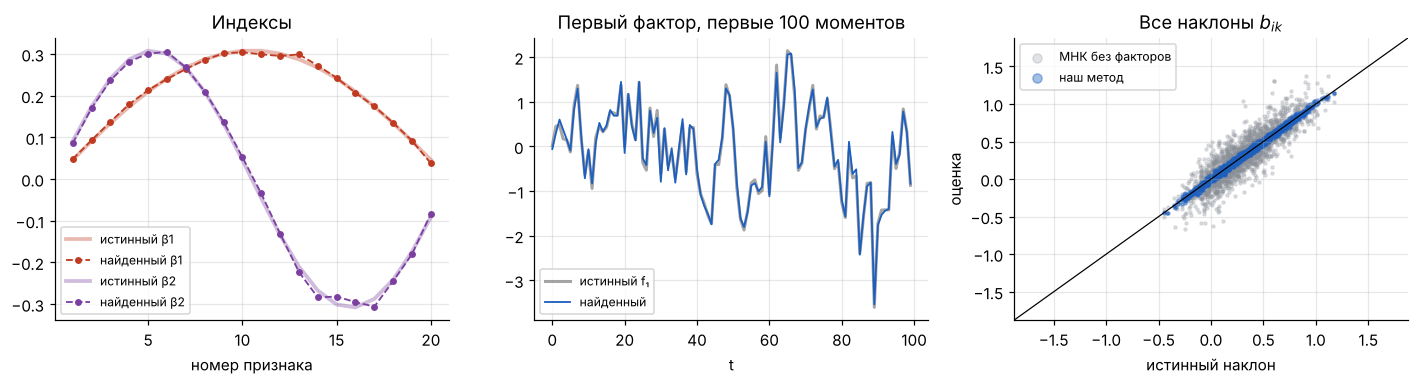

In [7]:
def align_rows(Ph, P):
    U, _, Vt = np.linalg.svd(P @ Ph.T)
    return (U @ Vt) @ Ph

Pal = align_rows(R['P'], D['P'])
Fal = R['F'] @ np.linalg.lstsq(R['F'], D['F'], rcond=None)[0]
Bols = res['МНК'][0]

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
j = np.arange(1, D['P'].shape[1] + 1)
for k, c in enumerate(['#bf3a20', '#7b3fa0']):
    axs[0].plot(j, D['P'][k], color=c, lw=2.5, alpha=0.35, label=f'истинный β{k + 1}')
    axs[0].plot(j, Pal[k], 'o--', color=c, ms=3.5, lw=1.2, label=f'найденный β{k + 1}')
axs[0].set_title('Индексы'); axs[0].set_xlabel('номер признака'); axs[0].legend(fontsize=8)

tt = np.arange(100)
axs[1].plot(tt, D['F'][:100, 0], color='k', lw=2, alpha=0.35, label='истинный f₁')
axs[1].plot(tt, Fal[:100, 0], color=COL['ours'], lw=1.2, label='найденный')
axs[1].set_title('Первый фактор, первые 100 моментов'); axs[1].set_xlabel('t'); axs[1].legend(fontsize=8)

lim = np.abs(D['B']).max() * 1.6
axs[2].scatter(D['B'].ravel(), Bols.ravel(), s=4, alpha=0.25, color=COL['ols'], label='МНК без факторов')
axs[2].scatter(D['B'].ravel(), R['B'].ravel(), s=4, alpha=0.4, color=COL['ours'], label='наш метод')
axs[2].plot([-lim, lim], [-lim, lim], 'k-', lw=0.8)
axs[2].set_xlim(-lim, lim); axs[2].set_ylim(-lim, lim)
axs[2].set_xlabel('истинный наклон'); axs[2].set_ylabel('оценка'); axs[2].set_title('Все наклоны $b_{ik}$')
axs[2].legend(fontsize=8, markerscale=3)
plt.tight_layout(); plt.show()

## 4. Как выбрать $r$ и $m$

Слева — сингулярные числа центрированной матрицы остатков $\widetilde W$ после оценки с запасом, $r=6$: число факторов видно по «локтю». Справа — сингулярные числа матрицы наклонов, оценённой МНК по каждому индивиду с начальными факторами (тоже с запасом, $r=6$): число индексов видно так же.

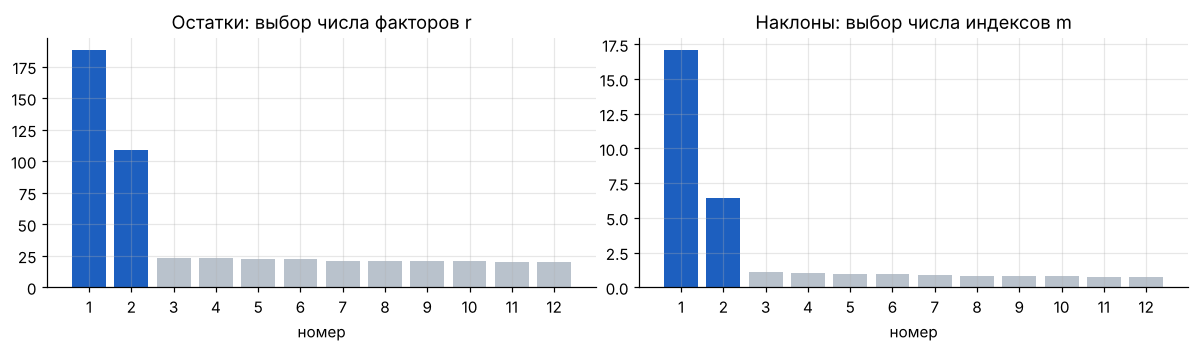

остатки: [188.3 109.2  23.4  23.2  22.7  22. ]
наклоны: [17.1   6.4   1.07  1.01  0.98  0.93]


In [8]:
Rbig = fit(D['Y'], D['X'], m=2, r=6)
_, s_res = factor_step(D['Y'], D['X'], Rbig['B'], 6)
F0 = init_factors(D['Y'], D['X'], 6)
s_B = np.linalg.svd(ols_slopes(*proj_stats(D['X'], D['Y'], basis(F0, 200))), compute_uv=False)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.3))
k = np.arange(1, 13)
axs[0].bar(k, s_res[:12], color=[COL['ours'] if i < 2 else '#b9c2cc' for i in range(12)])
axs[0].set_title('Остатки: выбор числа факторов r'); axs[0].set_xlabel('номер'); axs[0].set_xticks(k)
axs[1].bar(k, s_B[:12], color=[COL['ours'] if i < 2 else '#b9c2cc' for i in range(12)])
axs[1].set_title('Наклоны: выбор числа индексов m'); axs[1].set_xlabel('номер'); axs[1].set_xticks(k)
plt.tight_layout(); plt.show()
print('остатки:', np.round(s_res[:6], 1))
print('наклоны:', np.round(s_B[:6], 2))

## 5. Зависимость от длины рядов $T$

Для каждого $T$ генерируем 30 наборов данных и усредняем ошибку наклонов. Пунктир — наклон $1/\sqrt T$.

время: 28 с


,МНК,многоиндексный,МНК-оракул,многоиндексный оракул,наш метод
T,,,,,
30,1.067,0.462,0.985,0.172,0.174
50,0.643,0.424,0.472,0.125,0.127
100,0.479,0.400,0.277,0.086,0.087
200,0.414,0.394,0.181,0.059,0.060
400,0.388,0.400,0.124,0.041,0.042


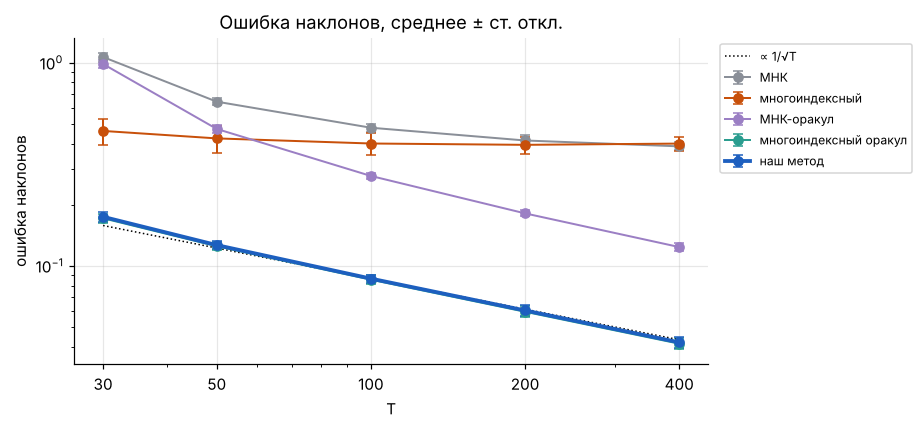

In [9]:
Ts = [30, 50, 100, 200, 400]
names = ['МНК', 'многоиндексный', 'МНК-оракул', 'многоиндексный оракул', 'наш метод']
keys = ['ols', 'lr', 'ols_or', 'lr_or', 'ours']
REP = 30
err = {nm: np.zeros((len(Ts), REP)) for nm in names}
t0 = time.time()
for a, T in enumerate(Ts):
    for s in range(REP):
        Dm = make_data(n=100, T=T, d=20, conf=0.5, seed=1000 + s)
        rs, _ = all_methods(Dm)
        for nm in names:
            err[nm][a, s] = rel_err(rs[nm][0], Dm['B'])
print(f'время: {time.time() - t0:.0f} с')

summary_T = pd.DataFrame({nm: err[nm].mean(1) for nm in names}, index=pd.Index(Ts, name='T'))
display(summary_T.round(3))

fig, ax = plt.subplots(figsize=(8.5, 4))
for nm, k in zip(names, keys):
    ax.errorbar(Ts, err[nm].mean(1), yerr=err[nm].std(1), fmt='o-', color=COL[k], capsize=3, label=nm,
                lw=2.5 if k == 'ours' else 1.3)
ref = err['наш метод'].mean(1)[2] * np.sqrt(100 / np.array(Ts))
ax.plot(Ts, ref, 'k:', lw=1, label='∝ 1/√T')
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xticks(Ts); ax.set_xticklabels(Ts)
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel('T'); ax.set_ylabel('ошибка наклонов'); ax.set_title('Ошибка наклонов, среднее ± ст. откл.')
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()

## 6. Наблюдений меньше, чем признаков

Пусть $d=40$, а $T=30$. Регрессию по каждому индивиду построить нельзя: неизвестных больше, чем наблюдений. Многоиндексной модели это не мешает, потому что на индивида приходится всего $m=2$ неизвестных нагрузки, а индексы оцениваются по всем индивидам сразу. Старт в этом случае случайный.

In [10]:
rows = []
for s in range(10):
    Ds = make_data(n=100, T=30, d=40, conf=0.5, seed=2000 + s)
    Rs = fit(Ds['Y'], Ds['X'], m=2, r=2)
    rows.append([rel_err(Rs['B'], Ds['B']), sin_angle(Rs['P'], Ds['P']), len(Rs['hist'])])
small = pd.DataFrame(rows, columns=['ошибка наклонов', 'угол индексов', 'итераций'])
small.describe().loc[['mean', 'std', 'min', 'max']].round(3)

,ошибка наклонов,угол индексов,итераций
mean,0.188,0.179,8.400
std,0.014,0.027,0.516
min,0.174,0.131,8.000
max,0.212,0.226,9.000


## 7. Ошибка в числе факторов

Истинное $r=2$. Запускаем алгоритм с $r=0,1,\dots,8$, по 20 наборов данных на каждое значение.

,ошибка наклонов,ст. откл.
r,,
0,0.377,0.039
1,0.234,0.025
2,0.059,0.003
3,0.061,0.003
4,0.062,0.004
6,0.063,0.003
8,0.065,0.003


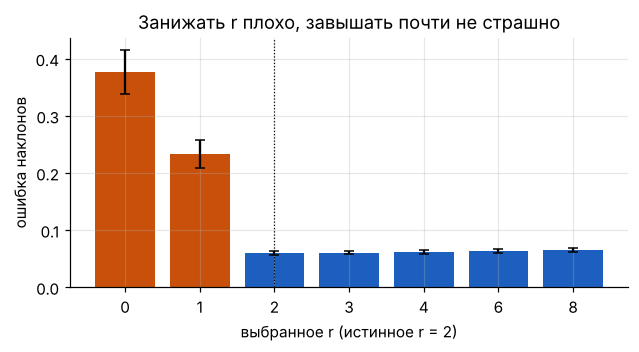

In [11]:
rs_list = [0, 1, 2, 3, 4, 6, 8]
E = np.zeros((len(rs_list), 20))
for s in range(20):
    Dr = make_data(n=100, T=200, d=20, conf=0.5, seed=3000 + s)
    for a, rr in enumerate(rs_list):
        E[a, s] = rel_err(fit(Dr['Y'], Dr['X'], m=2, r=rr)['B'], Dr['B'])
summary_r = pd.DataFrame({'ошибка наклонов': E.mean(1), 'ст. откл.': E.std(1)}, index=pd.Index(rs_list, name='r'))
display(summary_r.round(3))

fig, ax = plt.subplots(figsize=(6, 3.3))
ax.bar([str(v) for v in rs_list], E.mean(1), yerr=E.std(1), capsize=3,
       color=[COL['lr'] if v < 2 else COL['ours'] for v in rs_list])
ax.axvline(2, color='k', lw=0.8, ls=':')
ax.set_xlabel('выбранное r (истинное r = 2)'); ax.set_ylabel('ошибка наклонов')
ax.set_title('Занижать r плохо, завышать почти не страшно')
plt.tight_layout(); plt.show()

## 8. Сила связи признаков с факторами

Меняем `conf` от 0 (признаки не зависят от факторов) до 1. Сравниваем многоиндексную модель без учёта факторов (раздел 2) и наш метод, по 20 наборов данных на точку.

,многоиндексный,наш метод
conf,,
0.00,0.115,0.061
0.25,0.305,0.061
0.50,0.396,0.061
0.75,0.409,0.061
1.00,0.401,0.062


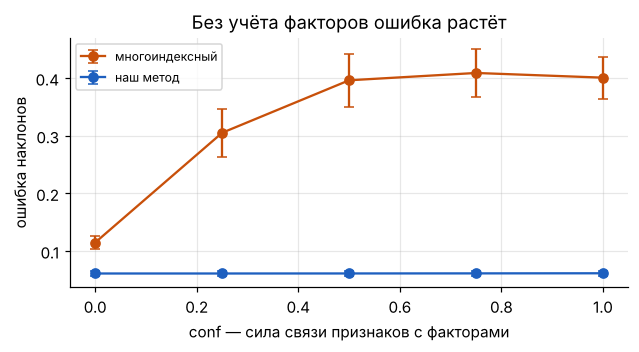

In [12]:
confs = [0.0, 0.25, 0.5, 0.75, 1.0]
E2 = {'многоиндексный': np.zeros((len(confs), 20)), 'наш метод': np.zeros((len(confs), 20))}
for a, cf in enumerate(confs):
    for s in range(20):
        Dc = make_data(n=100, T=200, d=20, conf=cf, seed=4000 + s)
        G, Z = proj_stats(Dc['X'], Dc['Y'], basis(None, 200))
        _, _, Bl = lowrank_slopes(G, Z, principal_axes(ols_slopes(G, Z), 2), iters=50)
        E2['многоиндексный'][a, s] = rel_err(Bl, Dc['B'])
        E2['наш метод'][a, s] = rel_err(fit(Dc['Y'], Dc['X'], m=2, r=2)['B'], Dc['B'])
summary_c = pd.DataFrame({k: v.mean(1) for k, v in E2.items()}, index=pd.Index(confs, name='conf'))
display(summary_c.round(3))

fig, ax = plt.subplots(figsize=(6, 3.3))
for k, c in [('многоиндексный', COL['lr']), ('наш метод', COL['ours'])]:
    ax.errorbar(confs, E2[k].mean(1), yerr=E2[k].std(1), fmt='o-', capsize=3, color=c, label=k)
ax.set_xlabel('conf — сила связи признаков с факторами'); ax.set_ylabel('ошибка наклонов')
ax.set_title('Без учёта факторов ошибка растёт'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 9. Почему шаг через проекцию сходится быстро

Сравним наш алгоритм с более привычной схемой чередования по остаткам: при фиксированных факторах и нагрузках $\gamma_i$ из отклика вычитают факторную часть $\gamma_i^\top f_t$ и оценивают наклоны, потом по остаткам заново оценивают $F$ и $\gamma_i$. В нашем шаге по наклонам $\gamma_i$ и $c_i$ исключаются проекцией $M_F$, то есть оптимизируются вместе с наклонами. Обе схемы минимизируют одну и ту же функцию $S$ и приходят к одному ответу, но с разной скоростью. По 10 наборов данных на каждое значение `conf`.

In [13]:
rows = []
for cf in [0.5, 1.0, 2.0]:
    for s in range(10):
        Dq = make_data(n=100, T=200, d=20, conf=cf, seed=9000 + s)
        t0 = time.time(); R1 = fit(Dq['Y'], Dq['X'], 2, 2); t1 = time.time() - t0
        t0 = time.time(); R2 = fit_resid(Dq['Y'], Dq['X'], 2, 2); t2 = time.time() - t0
        rows.append([cf, len(R1['hist']), len(R2['hist']), rel_err(R1['B'], Dq['B']), rel_err(R2['B'], Dq['B']),
                     np.linalg.norm(R1['B'] - R2['B']) / np.linalg.norm(Dq['B']), t1, t2])
cmp = pd.DataFrame(rows, columns=['conf', 'итер. проекция', 'итер. по остаткам', 'ошибка проекция',
                                  'ошибка по остаткам', 'расхождение', 'время проекция, с', 'время по остаткам, с'])
cmp.groupby('conf').mean().round(4)

,итер. проекция,итер. по остаткам,ошибка проекция,ошибка по остаткам,расхождение,"время проекция, с","время по остаткам, с"
conf,,,,,,,
0.5,5.7,32.7,0.0605,0.0605,0.0000,0.1252,0.4395
1.0,6.0,109.2,0.0609,0.0609,0.0000,0.1354,1.4082
2.0,8.5,432.6,0.0622,0.0622,0.0001,0.1698,5.5644


## Итоги

1. **Сходимость.** Алгоритм сходится за несколько итераций: 5 в основном примере, 8–9 при $T<d$. Значение $S$ на каждой итерации не растёт.
2. **Смещение без учёта факторов.** Если признаки связаны с факторами, ошибка МНК и многоиндексной модели раздела 2 около 0.4 и не уменьшается с ростом $T$: при $T=400$ она 0.39 и 0.40. Это смещение, а не шум.
3. **Наш метод почти как оракул.** Ошибка почти совпадает с многоиндексным оракулом, которому факторы известны: при $T=200$ это 0.060 против 0.059. Она убывает примерно как $1/\sqrt T$. На графике по $T$ линии нашего метода и оракула сливаются.
4. **Выигрыш от низкого ранга.** МНК даже с истинными факторами ошибается втрое сильнее (0.181 при $T=200$): он оценивает 20 наклонов на индивида, а не две нагрузки.
5. **Мало наблюдений.** При $d=40$ и $T=30$ регрессию по каждому индивиду построить нельзя, а наш метод из случайного старта даёт ошибку около 0.19.
6. **Число факторов.** Занижать $r$ нельзя: при $r=0$ ошибка 0.38, при $r=1$ — 0.23. Завышение до $r=8$ увеличивает её лишь с 0.059 до 0.065, поэтому $r$ лучше брать с запасом.
7. **Учёт факторов полезен и без смещения.** Даже если признаки не связаны с факторами (`conf = 0`), их учёт вдвое уменьшает ошибку (0.115 → 0.061): факторная часть перестаёт быть шумом.
8. **Выбор $r$ и $m$.** И число факторов, и число индексов хорошо видны по «локтю» сингулярных чисел.
9. **Скорость.** Шаг через проекцию сходится за 6–9 итераций, а чередование по остаткам при той же точности требует десятки и сотни итераций, и чем сильнее признаки связаны с факторами, тем больше. Ответ у обеих схем один и тот же.

Что можно проверить дальше:
- гетероскедастичный и автокоррелированный шум $\varepsilon_{it}$;
- слабые факторы, затрагивающие малую долю индивидов;
- сравнение с оценкой Песарана (CCE);
- доверительные интервалы для наклонов.